# One turbine: five power curves and the price of physics

This notebook fits five power models to one Penmanshiel turbine on a **training
window only** and scores them on a later window that no model saw. It runs the
same pipeline as `run_poc.py`, in fewer cells and without the farm.

Data: Plumley & Takeuchi, *Penmanshiel wind farm data*, Zenodo,
[doi:10.5281/zenodo.16807304](https://doi.org/10.5281/zenodo.16807304), CC-BY-4.0.
The download commands are in `examples/wind_farm_penmanshiel/README.md`.

## Setup

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt

from pinneapple_systems import wind
from pinneapple_systems.wind import figures

warnings.filterwarnings("ignore", category=FutureWarning)

RAW = Path(os.environ.get("PENMANSHIEL_RAW", Path.home() / "pn-wind-data" / "raw"))
CACHE = Path(os.environ.get("PENMANSHIEL_CACHE", Path.home() / "pn-wind-data" / "cache"))
assert (RAW / "Penmanshiel_WT_static.csv").exists(), (
    f"no Penmanshiel data in {RAW}; see examples/wind_farm_penmanshiel/README.md for the download"
)
RATED, ROTOR, HUB = 2050.0, 82.0, 59.0

## Load one turbine and apply the recorded operating mask

The export carries the operator's own availability, downtime and curtailment
columns, so the mask is evidence rather than a heuristic. Every rule reports how
much it removed.

In [2]:
TURBINE = "T01"
raw = wind.load_turbine(RAW, TURBINE, cache_dir=CACHE)
raw = wind.add_density_correction(raw, elevation_m=204.0)

report = wind.qc_report(raw, rated_power_kw=RATED)
print(f"{report['rows']:,} rows, {report['span']['start'][:10]} to {report['span']['end'][:10]}")
print(f"operating: {report['operating_samples']:,} ({report['operating_fraction']:.1%})"
      f"   curtailed: {report['curtailed_samples']:,}")
print("mask provenance:", report["mask_provenance"]["curtailment_columns"],
      report["mask_provenance"]["downtime_columns"])

raw["operating"] = wind.operating_mask(raw, rated_power_kw=RATED)
data = raw[raw["operating"]]

# Region 2 only: below rated speed the machine is chasing maximum Cp, above it
# the pitch controller is deliberately spilling power, so a Cp averaged over both
# regions measures the controller, not the rotor.
region2 = data[(data.u_corrected > 5.0) & (data.u_corrected < 9.0)]
cp = region2.power_kw / (0.5 * wind.RHO_REF * np.pi * (ROTOR / 2) ** 2 * region2.u_corrected ** 3 / 1000)
print(f"median Cp in region 2 (5-9 m/s): {cp.median():.3f}   "
      f"implied by {len(region2):,} samples, against the Betz limit {wind.betz_limit():.3f}")

82,547 rows, 2016-06-06 to 2017-12-31
operating: 67,745 (82.1%)   curtailed: 0
mask provenance: ['lost_production_curtailment_kwh', 'power_setpoint_kw'] ['lost_production_downtime_kwh', 'data_availability']
median Cp in region 2 (5-9 m/s): 0.445   implied by 35,437 samples, against the Betz limit 0.593


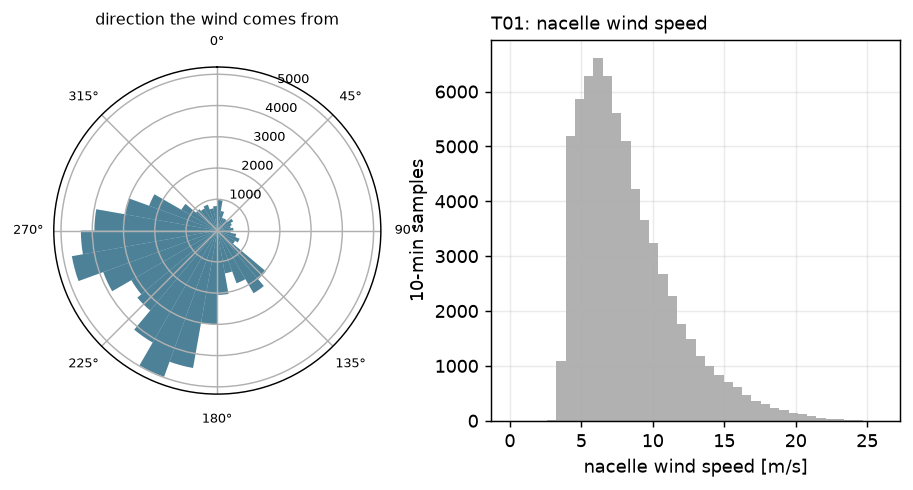

In [3]:
fig = figures.plot_wind_rose(data, title=f"{TURBINE}: nacelle wind speed")
plt.show()

## The split

Train on everything before July 2017, validate on July-August, test on
September-December. Nothing is shuffled and no lagged target is used: the test
window is 3-15 months after the last training sample.

In [4]:
TRAIN_END, VAL_END = pd.Timestamp("2017-07-01"), pd.Timestamp("2017-09-01")
train = data[data.timestamp < TRAIN_END]
val = data[(data.timestamp >= TRAIN_END) & (data.timestamp < VAL_END)]
test = data[data.timestamp >= VAL_END]
print(f"train {len(train):,}   validation {len(val):,}   test {len(test):,}")

train 44,312   validation 7,469   test 15,964


## Fit the five models

- **reference** — the analytic curve a datasheet carries (cubic to rated, Cp = 0.45);
- **IEC binned** — the 61400-12-1 measured curve, 0.5 m/s bins;
- **logistic** — five parameters, the smooth fit most commercial tools use;
- **physics-informed** — a monotone hinge network whose constraints hold by construction;
- **boosted trees** — the conventional ML baseline, on the same input.

Plus the operator's own `Potential power default PC` column as a yardstick that
this package did **not** fit.

In [5]:
from pinneapple_systems import wind
from pinneapple_systems.wind.models import feature_matrix

speed, power = train.u_corrected.to_numpy(float), train.power_kw.to_numpy(float)

reference = wind.ReferencePowerCurve(RATED, ROTOR, cut_in=3.0, cut_out=25.0)
binned = wind.fit_binned_curve(speed, power, cut_out=25.0, min_count=20)
logistic = wind.fit_logistic_curve(speed, power, rated_power_kw=RATED, cut_in=3.0, cut_out=25.0)
pi_model = wind.PhysicsInformedPowerModel(
    rated_power_kw=RATED, rotor_diameter=ROTOR, hub_height=HUB, cut_in=3.0, cut_out=25.0,
).fit(feature_matrix(train, ("u_corrected",)), power)
gbm = wind.GradientBoostedPowerModel(feature_names=("u_corrected",)).fit(
    feature_matrix(train, ("u_corrected",)), power)

models = {
    "reference (analytic)":   wind.SpeedCurveModel(reference.power, name="reference", kind="reference"),
    "IEC binned":             wind.SpeedCurveModel(binned.power, name="binned", kind="empirical"),
    "logistic":               wind.SpeedCurveModel(logistic.power, name="logistic", kind="empirical"),
    "physics-informed":       pi_model,
    "boosted trees":          gbm,
    "operator potential PC":  wind.FrameColumnModel(),
}
print("fitted; the physics-informed region-2 Cp is",
      round(pi_model.diagnostics["implied_cp_region2"], 3), "against Betz", round(wind.betz_limit(), 3))

fitted; the physics-informed region-2 Cp is 0.43 against Betz 0.593


## Score them on the test window

In [6]:
def predict(model, frame):
    if getattr(model, "reads_frame", False):
        return model.predict(frame)
    return model.predict(feature_matrix(frame, model.feature_names))

rows = {}
for label, model in models.items():
    m = wind.point_metrics(test.power_kw.to_numpy(float), predict(model, test))
    rows[label] = {
        "RMSE [kW]": round(m.rmse_kw, 1),
        "MAE [kW]": round(m.mae_kw, 1),
        "RMSE weighted by energy [kW]": round(m.energy_weighted_rmse_kw, 1),
        "R2": round(m.r2, 4),
        "energy error": f"{m.energy_error_fraction:+.1%}",
    }
pd.DataFrame(rows).T

,RMSE [kW],MAE [kW],RMSE weighted by energy [kW],R2,energy error
reference (analytic),102.6,66.4,130.7,0.9767,+4.3%
IEC binned,46.6,34.4,53.5,0.9952,-0.6%
logistic,48.9,36.0,55.1,0.9947,-0.2%
physics-informed,54.3,38.0,65.6,0.9935,+0.2%
boosted trees,46.7,34.4,53.4,0.9952,-0.6%
operator potential PC,57.1,40.9,64.0,0.9928,+2.1%


## Where each model stands on the physics

The interesting column is the last one. The IEC binned curve — the industry's
definition of a power curve — is not monotone, is not zero outside the cut-in /
cut-out window, and its noisy low-wind bins imply a Cp above the Betz limit.
The physics-informed model cannot make any of those mistakes, and it pays about
0.4 % of rated power for that.

In [7]:
def speed_curve(model, frame):
    if getattr(model, "reads_frame", False):
        return None
    names = tuple(model.feature_names)
    if names == ("u_corrected",):
        return lambda u: model.predict(np.column_stack([u]))
    med = {n: float(np.nanmedian(feature_matrix(frame, (n,))[:, 0])) for n in names}
    return lambda u: model.predict(np.column_stack(
        [u if n == "u_corrected" else np.full_like(u, med[n]) for n in names]))

checks = {}
for label, model in models.items():
    curve = speed_curve(model, train)
    if curve is None:
        continue
    checks[label] = {
        c["name"].replace("conservation_", ""): ("pass" if c["passed"] else "FAIL")
        for c in wind.physical_guardrails(curve, rated_power_kw=RATED, cut_in=3.0, cut_out=25.0,
                                          rotor_diameter=ROTOR)
    }
pd.DataFrame(checks).T

,power_cap,monotonicity,operating_window,betz_limit
reference (analytic),pass,pass,pass,pass
IEC binned,pass,FAIL,FAIL,FAIL
logistic,pass,pass,pass,pass
physics-informed,pass,pass,pass,pass
boosted trees,pass,FAIL,FAIL,FAIL


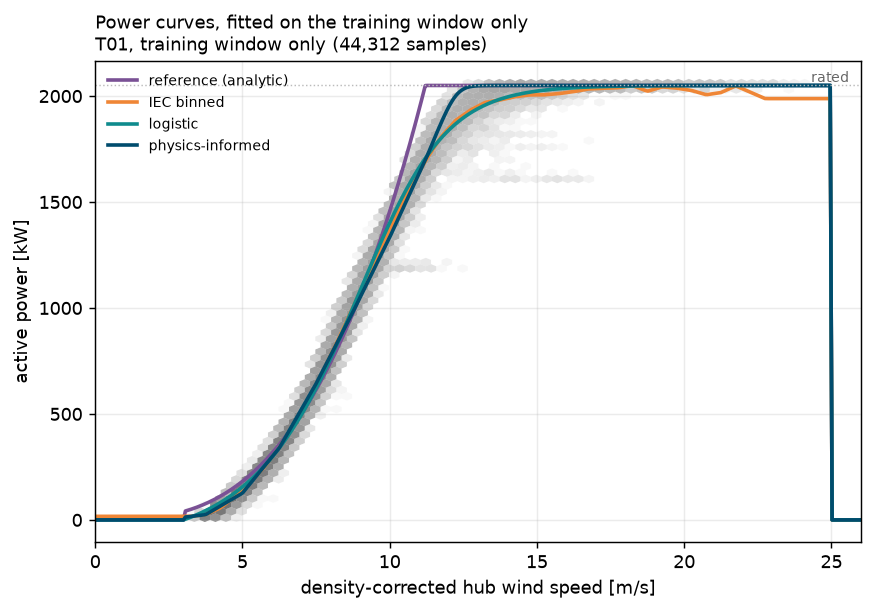

In [8]:
curves = {
    "reference (analytic)": reference.power,
    "IEC binned": binned.power,
    "logistic": logistic.power,
    "physics-informed": lambda u: pi_model.predict(np.column_stack([u])),
}
fig = figures.plot_power_curves(curves, train, rated_power_kw=RATED,
                                     subtitle=f"{TURBINE}, training window only ({len(train):,} samples)")
plt.show()

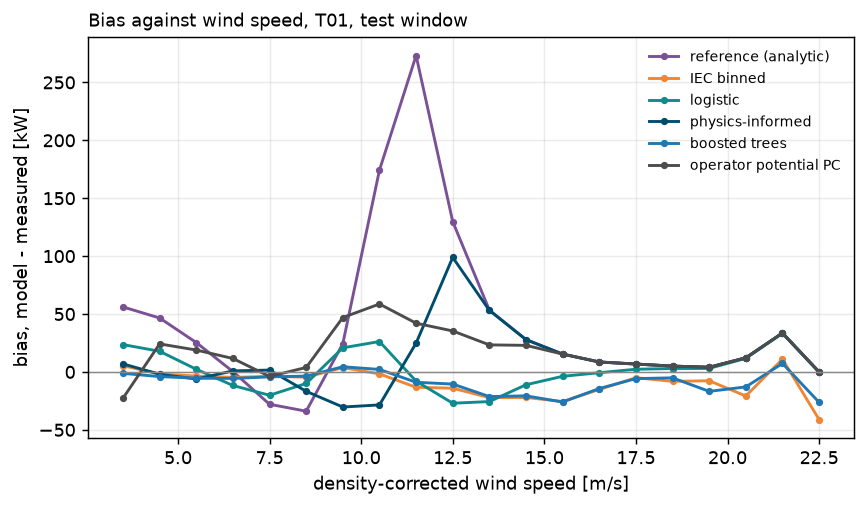

In [9]:
fig = figures.plot_error_by_speed(
    {label: wind.per_bin_error(test.u_corrected.to_numpy(float), test.power_kw.to_numpy(float),
                               predict(model, test), bin_width=1.0)
     for label, model in models.items()},
    title=f"Bias against wind speed, {TURBINE}, test window")
plt.show()

## How much the prediction deserves to be trusted

A split-conformal interval is built on the **validation** residuals and its
coverage is measured on the **test** window. The gap between the target and the
measured coverage is the honest part: a year-later window is not exchangeable
with the calibration one.

In [10]:
residual_val = val.power_kw.to_numpy(float) - predict(pi_model, val)
half_width = wind.conformal_interval(residual_val, level=0.9)
residual_test = test.power_kw.to_numpy(float) - predict(pi_model, test)
print(f"half-width {half_width:.0f} kW at a 90 % target")
print(wind.calibration_report(residual_test, half_width))

half-width 80 kW at a 90 % target
{'n': 15964, 'coverage': 0.8765347030819344, 'mean_abs_residual_kw': 37.97455724538394, 'p90_abs_residual_kw': 88.13740234375327}


## The applicability map

The last word belongs to VeriPhysics: what was verified, what is only inferred,
and where the model must not be asked to extrapolate.

In [11]:
envelope = {
    "wind_speed": (float(train.u_corrected.quantile(0.001)), float(train.u_corrected.quantile(0.999))),
    "relative_density": (float(train.rho_relative.quantile(0.001)), float(train.rho_relative.quantile(0.999))),
}
m = wind.point_metrics(test.power_kw.to_numpy(float), predict(pi_model, test))
app = wind.power_applicability_map(
    architecture="physics-informed monotone hinge network (25 knots, hard cap and operating gate)",
    train=train, test_metrics=m.to_dict(),
    guardrails=wind.physical_guardrails(lambda u: pi_model.predict(np.column_stack([u])),
                                        rated_power_kw=RATED, cut_in=3.0, cut_out=25.0,
                                        rotor_diameter=ROTOR),
    calibration={"half_width_kw": half_width, "target_coverage": 0.9,
                 "coverage": wind.calibration_report(residual_test, half_width)["coverage"]},
    bounds=envelope, rmse_threshold_kw=0.05 * RATED, loss_history=pi_model.history,
    epochs=pi_model.epochs, n_parameters=int(pi_model.theta.size * 2),
    loss_weights={"data": 1.0, "cubic_region2": pi_model.cubic_weight,
                  "smoothness": pi_model.smoothness_weight, "betz": pi_model.betz_weight},
)
print(app.render())

Applicability map (evidence chain)

Review checklist:
  [INFO] What surrogate is this? (verified)
      architecture=physics-informed monotone hinge network (25 knots, hard cap and operating gate); inputs=['wind_speed', 'relative_density']; outputs=['power_kw']; 50 trainable parameters
  [PASS] What is the error? (verified)
      Residual and/or reference mismatch below.
  [PASS] Did it converge? (verified)
      Optimizer and numerical convergence evidence below.
  [PASS] Can it generalize? (verified)
      rmse_kw=54.35 (threshold 102.5)
  [INFO] Which variables, and over what range? (verified)
      2 coordinate(s), 1 fixed parameter(s), 0 parameter range(s), 1 field(s); see the variable envelope.
  [INFO] Which loss weights? (verified)
      Explicit loss weights: data=1, cubic_region2=0.05, smoothness=0.001, betz=5. Sensitivity was not swept; the verification residual is re-computed independently of these weights.
  [PASS] Uncertainty quantification? (verified)
      Calibrated ag

### What this notebook does not establish

The test window lies entirely inside the training envelope, so this is an
**interpolation** test. The operator's potential-power column is fitted by the
operator over years of data this notebook does not use; it is a yardstick, not a
competitor. And no curve here has been checked against a met mast.